In [1]:
import pickle
import numpy as np

from particle_filter.filtering_algorithms.kalman_filter import KalmanFilter 
from particle_filter.filtering_algorithms.particle_filter import BootstrapParticleFilter, AuxiliaryParticleFilter

from particle_filter.models.noise import GaussianNoise
from particle_filter.models.transition import AdditiveTransitionModel
from particle_filter.models.observation import AdditiveObservationModel

from particle_filter.simulations import system_simulation

from particle_filter.plots.plot_results import plot_results
from particle_filter.plots.plot_comparisons import plot_comparisons
from particle_filter.plots.plot_EES import plot_ESS

from particle_filter.performance_metrics import RMSE, Interval_cover

En este notebook se presentan una serie de ejemplos lineales comparando entre el Bootstrap Filter y el Auxiliary Particle Filter

# MODELO DE ESPACIO EN ESTADOS

Para todos los casos, se define un sistema lineal y Gaussiano.

- Ecuación de estado:

$$
x_t = A x_{t-1} + w_t, \;\;\; w_t \sim N(0,Q)
$$

- Ecuación de medición

$$
y_t = H x_t + v_t, \;\;\; v_t \sim N(0,R)
$$

### Convergencia del filtro de partículas hacia el filtro de Kalman

El filtro de Kalman es el estimador BLUE ($\textit{Best Linear Unbiased Estimator}$) para un sistma dinámico cuando el modelo y el ruido son lineales y gaussianos. Es decir, es el que menos se equivoca porque tiene la varianza más pequeña.

En este primer apartado se va a comprobar cómo al ir aumentando el número de partículas, el filtro de partículas converge al filtro de Kalman por la ley de los grandes números.

Se va a tomar como ejemplo un sistema de la siguiente forma (Saarka: Exercise 7.1):

$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 
\end{bmatrix}
\;\;
Q = \begin{bmatrix}
0.01 &0 \\
0 &1
\end{bmatrix}
\;\;
R = \begin{bmatrix}
1 
\end{bmatrix}
$$

La comparación se va a realizar comparando el RMSE para el Bootstrap Particle Filter y el Auxiliary Particle Filter (ambos con re-muestreo).

In [10]:
# Definición matrices de transición, observación y ruidos

A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

Q = np.array([
    [0.01, 0.0],
    [0.0, 1.]
])

R = np.array([[1.]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [11]:
# Definición de los modelos de transición y observación
noise_transition = GaussianNoise(Q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(R)
observation = AdditiveObservationModel(h, noise_observation)

In [13]:
n_simulations = 10

T = 100
x0 = np.array([0.0, 0.0])

simulations = []

for i in range(n_simulations):

    x_true, y_obs = system_simulation(transition, observation, x0, T)

    simulations.append({
        "n_simulation": i,
        "x_true": x_true,
        "y_obs": y_obs
    }) 

    print(f"Simulacion {i} finalizada")

with open("simulation.pkl", "wb") as file:
    pickle.dump(simulations, file)

Simulacion 0 finalizada
Simulacion 1 finalizada
Simulacion 2 finalizada
Simulacion 3 finalizada
Simulacion 4 finalizada
Simulacion 5 finalizada
Simulacion 6 finalizada
Simulacion 7 finalizada
Simulacion 8 finalizada
Simulacion 9 finalizada


In [14]:
# Numero de partículas
N_particles = [10, 50, 100, 250, 500, 1000]

- Bootstrap Particle Filter

In [19]:
# Ejecucion Bootstrap Particle Filter
results_bpf = {n: [] for n in N_particles}

for n in N_particles:

    for i in range(n_simulations):

        x_true = simulations[i]["x_true"]
        y_obs = simulations[i]["y_obs"]

        bpf = BootstrapParticleFilter(
            N=n,
            transition_model=transition,
            observation_model=observation
        )

        bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

        est_bpf = bpf.run_filter(y_obs)

        results_bpf[n].append({
            "n_simulation": i,
            "N_particles": n,
            "x_true": x_true,
            "y_obs": y_obs,
            "results": est_bpf
        })

    print(f"Bootstrap con {n} partículas finalizado")

Bootstrap con 10 partículas finalizado
Bootstrap con 50 partículas finalizado
Bootstrap con 100 partículas finalizado
Bootstrap con 250 partículas finalizado
Bootstrap con 500 partículas finalizado
Bootstrap con 1000 partículas finalizado


- Auxiliary Particle Filter

In [20]:
# Ejecucion Bootstrap Particle Filter
results_apf = {n: [] for n in N_particles}

for n in N_particles:

    for i in range(n_simulations):

        x_true = simulations[i]["x_true"]
        y_obs = simulations[i]["y_obs"]

        apf = AuxiliaryParticleFilter(
            N=n,
            transition_model=transition,
            observation_model=observation
        )

        apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

        est_apf = apf.run_filter(y_obs)

        results_apf[n].append({
            "n_simulation": i,
            "N_particles": n,
            "x_true": x_true,
            "y_obs": y_obs,
            "results": est_apf
        })

    print(f"Auxiliary con {n} partículas finalizado")

Auxiliary con 10 partículas finalizado
Auxiliary con 50 partículas finalizado
Auxiliary con 100 partículas finalizado
Auxiliary con 250 partículas finalizado
Auxiliary con 500 partículas finalizado
Auxiliary con 1000 partículas finalizado


- Kalman Filter

In [16]:
# Ejecucion Bootstrap Particle Filter
results_kf = []

for i in range(n_simulations):

    x_true = simulations[i]["x_true"]
    y_obs = simulations[i]["y_obs"]

    x0 = np.array([0.0, 0.0])
    P0 = np.eye(2)

    kf = KalmanFilter(A, H, Q, R, x0, P0)
    est_kf = kf.run_filter(y_obs)

    results_kf.append({
        "n_simulation": i,
        "x_true": x_true,
        "y_obs": y_obs,
        "results": est_kf
    })


### Resultados estadísticos

In [12]:
with open ("results_10simulations_no_resampling.pkl", "rb") as file:

    results = pickle.load(file)

results_bpf = results["Bootstrap"]
results_apf = results["Auxiliary"]
results_kf = results["Kalman"]


In [13]:
N_particles = [10, 50, 100, 250, 500, 1000]
n_simulations = 10

# Calculo del RMSE BPF y APF
RMSE_bpf = {n: [] for n in N_particles}
RMSE_apf = {n: [] for n in N_particles}

RMSE_bpf_x1 = {n: [] for n in N_particles}
RMSE_apf_x1 = {n: [] for n in N_particles}

RMSE_bpf_x2 = {n: [] for n in N_particles}
RMSE_apf_x2 = {n: [] for n in N_particles}

for n in N_particles:

    for i in range(n_simulations):

        x_true = results_bpf[n][i]["x_true"]

        RMSE_bpf[n].append(RMSE(x_true, results_bpf[n][i]["results"]["estimates"]))
        RMSE_apf[n].append(RMSE(x_true, results_apf[n][i]["results"]["estimates"]))

        RMSE_bpf_x1[n].append(RMSE(x_true[:,0], results_bpf[n][i]["results"]["estimates"][:,0]))
        RMSE_bpf_x2[n].append(RMSE(x_true[:,1], results_bpf[n][i]["results"]["estimates"][:,1]))

        RMSE_apf_x1[n].append(RMSE(x_true[:,0], results_apf[n][i]["results"]["estimates"][:,0]))
        RMSE_apf_x2[n].append(RMSE(x_true[:,1], results_apf[n][i]["results"]["estimates"][:,1]))

In [14]:
RMSE_kf = []
RMSE_kf_x1 = []
RMSE_kf_x2 = []

for i in range(n_simulations):

    x_true = results_kf[i]["x_true"]

    RMSE_kf.append(RMSE(x_true, results_kf[i]["results"]["estimates"]))
    RMSE_kf_x1.append(RMSE(x_true[:,0], results_kf[i]["results"]["estimates"][:,0]))
    RMSE_kf_x2.append(RMSE(x_true[:,1], results_kf[i]["results"]["estimates"][:,1]))

mean_RMSE_kf = np.mean(RMSE_kf)
std_RMSE_kf = np.std(RMSE_kf, ddof=1)


In [15]:
mean_RMSE_bpf = []
std_RMSE_bpf = []

mean_RMSE_apf = []
std_RMSE_apf = []

for n in N_particles:

    mean_RMSE_bpf.append(np.mean(RMSE_bpf[n]))
    std_RMSE_bpf.append(np.std(RMSE_bpf[n], ddof=1))

    mean_RMSE_apf.append(np.mean(RMSE_apf[n]))
    std_RMSE_apf.append(np.std(RMSE_apf[n], ddof=1))

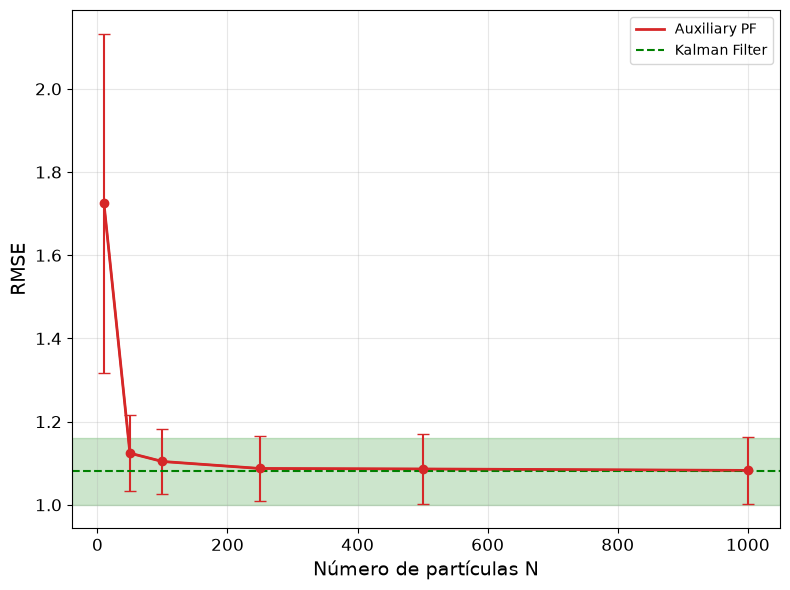

In [18]:
import matplotlib.pyplot as plt

# Plotear resultados
fig, ax = plot_comparisons(
    {
        #"Bootstrap PF": {"Número de partículas N": N_particles, "RMSE": mean_RMSE_bpf, "RMSE_errorbars": std_RMSE_bpf},
        "Auxiliary PF": {"Número de partículas N": N_particles, "RMSE": mean_RMSE_apf, "RMSE_errorbars": std_RMSE_apf}
    }, control_metric="Número de partículas N", performance_metric="RMSE", title="Comparación del RMSE según el número de partículas", show_errorbars=True)

ax.axhline(y=mean_RMSE_kf, linestyle='--', color="green", label="Kalman Filter")
ax.axhspan(mean_RMSE_kf - std_RMSE_kf, mean_RMSE_kf + std_RMSE_kf, color="green", alpha=0.2)

ax.legend() 

plt.show()

In [170]:
# Calculo de la log-verosimilitud BPF y APF
Loglikelihood_bpf = {n: [] for n in N_particles}
Loglikelihood_apf = {n: [] for n in N_particles}

for n in N_particles:

    for i in range(n_simulations):

        Loglikelihood_bpf[n].append(results_bpf[n][i]["results"]["log_likelihood"])
        Loglikelihood_apf[n].append(results_apf[n][i]["results"]["log_likelihood"])

In [171]:
mean_loglikelihood_bpf = []
std_loglikelihood_bpf = []

mean_loglikelihood_apf = []
std_loglikelihood_apf = []

for n in N_particles:

    mean_loglikelihood_bpf.append(np.mean(Loglikelihood_bpf[n]))
    std_loglikelihood_bpf.append(np.std(Loglikelihood_bpf[n], ddof=1))

    mean_loglikelihood_apf.append(np.mean(Loglikelihood_apf[n]))
    std_loglikelihood_apf.append(np.std(Loglikelihood_apf[n], ddof=1))

In [172]:
Loglikelihood_kf = []

for i in range(n_simulations):

    Loglikelihood_kf.append(results_kf[i]["results"]["loglikelihood"])

mean_Loglikelihood_kf = np.mean(Loglikelihood_kf)
std_Loglikelihood_kf = np.std(Loglikelihood_kf, ddof=1)


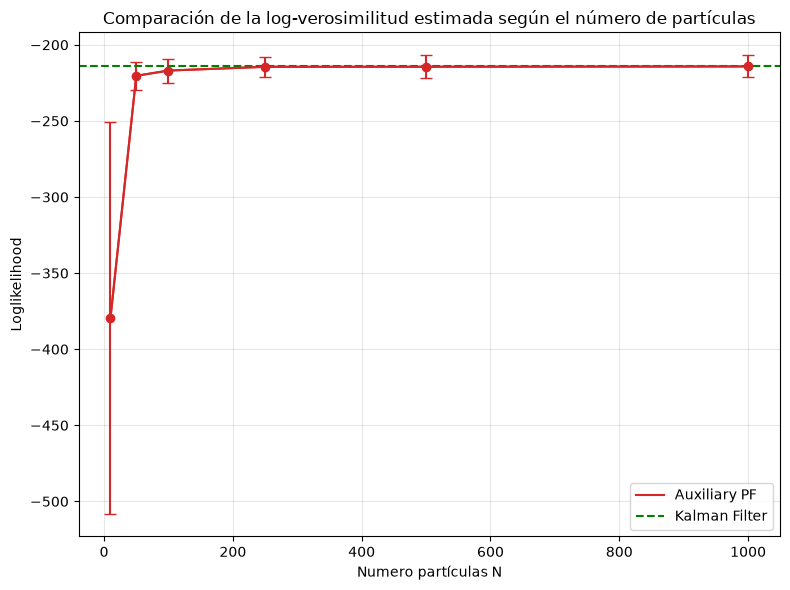

In [179]:
# Plotear resultados
fig, ax = plot_comparisons(
    {
        #"Bootstrap PF": {"Numero partículas N": N_particles, "Loglikelihood": mean_loglikelihood_bpf, "Loglikelihood_errorbars": std_loglikelihood_bpf},
        "Auxiliary PF": {"Numero partículas N": N_particles, "Loglikelihood": mean_loglikelihood_apf, "Loglikelihood_errorbars": std_loglikelihood_apf}
    }, control_metric="Numero partículas N", performance_metric="Loglikelihood", title="Comparación de la log-verosimilitud estimada según el número de partículas", show_errorbars=True)

ax.axhline(y=mean_Loglikelihood_kf, linestyle='--', color="green", label="Kalman Filter")
#ax.axhspan(mean_Loglikelihood_kf - std_Loglikelihood_kf, mean_Loglikelihood_kf + std_Loglikelihood_kf, color="green", alpha=0.2)
ax.legend() 

plt.show()

In [198]:
with open("results_10simulations_resampling.pkl", "rb") as file:

    results = pickle.load(file)

results_bpf_resampling = results["Bootstrap"]
results_apf_resampling = results["Auxiliary"]

In [199]:
# Calculo de la log-verosimilitud BPF y APF
time_execution_bpf = {n: [] for n in N_particles}
time_execution_apf = {n: [] for n in N_particles}
time_execution_bpf_r = {n: [] for n in N_particles}
time_execution_apf_r = {n: [] for n in N_particles}

for n in N_particles:

    for i in range(n_simulations):

        time_execution_bpf[n].append(results_bpf[n][i]["results"]["execution_time"])
        time_execution_apf[n].append(results_apf[n][i]["results"]["execution_time"])
        time_execution_bpf_r[n].append(results_bpf_resampling[n][i]["results"]["execution_time"])
        time_execution_apf_r[n].append(results_apf_resampling[n][i]["results"]["execution_time"])

In [200]:
mean_time_execution_bpf = []
std_time_execution_bpf = []

mean_time_execution_bpf_r = []
std_time_execution_bpf_r = []

mean_time_execution_apf = []
std_time_execution_apf = []

mean_time_execution_apf_r = []
std_time_execution_apf_r = []

for n in N_particles:

    mean_time_execution_bpf.append(np.mean(time_execution_bpf[n]))
    std_time_execution_bpf.append(np.std(time_execution_bpf[n], ddof=1))

    mean_time_execution_bpf_r.append(np.mean(time_execution_bpf_r[n]))
    std_time_execution_bpf_r.append(np.std(time_execution_bpf_r[n], ddof=1))

    mean_time_execution_apf.append(np.mean(time_execution_apf[n]))
    std_time_execution_apf.append(np.std(time_execution_apf[n], ddof=1))

    mean_time_execution_apf_r.append(np.mean(time_execution_apf_r[n]))
    std_time_execution_apf_r.append(np.std(time_execution_apf_r[n], ddof=1))

In [201]:
time_execution_kf = []

for i in range(n_simulations):

    time_execution_kf.append(results_kf[i]["results"]["execution_time"])

mean_time_execution_kf = np.mean(time_execution_kf)
std_time_execution_kf = np.std(time_execution_kf, ddof=1)

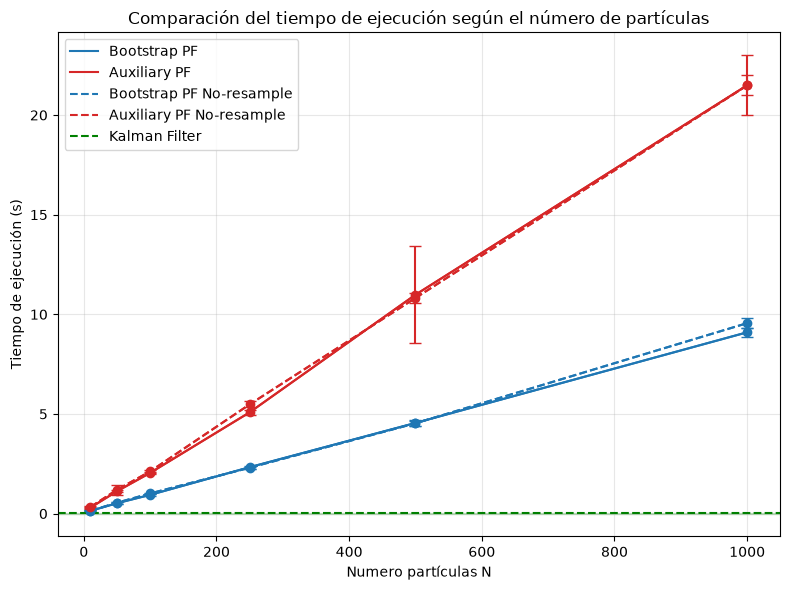

In [202]:
# Plotear resultados
fig, ax = plot_comparisons(
    {
        "Bootstrap PF": {"Numero partículas N": N_particles, "Tiempo de ejecución (s)": mean_time_execution_bpf_r, "Tiempo de ejecución (s)_errorbars": std_time_execution_bpf_r},
        "Auxiliary PF": {"Numero partículas N": N_particles, "Tiempo de ejecución (s)": mean_time_execution_apf_r, "Tiempo de ejecución (s)_errorbars": std_time_execution_apf_r},
        "Bootstrap PF No-resample": {"Numero partículas N": N_particles, "Tiempo de ejecución (s)": mean_time_execution_bpf, "Tiempo de ejecución (s)_errorbars": std_time_execution_bpf},
        "Auxiliary PF No-resample": {"Numero partículas N": N_particles, "Tiempo de ejecución (s)": mean_time_execution_apf, "Tiempo de ejecución (s)_errorbars": std_time_execution_apf}
    }, control_metric="Numero partículas N", performance_metric="Tiempo de ejecución (s)", title="Comparación del tiempo de ejecución según el número de partículas", show_errorbars=True)

ax.axhline(y=mean_time_execution_kf, linestyle='--', color="green", label="Kalman Filter")
ax.axhspan(mean_time_execution_kf - std_time_execution_kf, mean_time_execution_kf + std_time_execution_kf, color="green", alpha=0.2)
ax.legend() 

plt.show()

En las dos gráficas, se puede ver cómo el RMSE desciende rápidamente según el número de partículas con un dependencia $O(N^{1-/2})$. Es especialmente llamativo la gran diferencia en los valores del RMSE para 10 partículas entre el Bootstrap y el Auxiliary. Esto se puede deber a que dado que el último hace uso de las observaciones, ya tiene información para realizar un mejor filtrado. También mejor la log-verosimilitud

En algunos casos, se tiene un mejor resultado para los filtros de partículas que para el filtro de Kalman. Dado que el filtro de Kalman obtiene la mejor solución para el sistema que ocupa, esto podría parecer una contradicción, pero el caso es que esto este ejempo es para un caso concreto. Para varias simulaciones y varias ejecuciones, se tendría en promedio mejor resultado para el filtro de Kalman.


En cuánto al tiempo de ejecución se ve que aumenta a medida que el número de partículas crece. El mayor tiempo para el Auxiliary refleja el paso de actualización, pues es más laborioso que el caso del Bootstrap.

Para comparar, se dibujan los resultados del filtrado para $N=10$ y $N=5000$. En el primer caso, se ve una notable diferencia en los estados predichos por los filtros de partículas respecto al filtro de Kalman. Esta diferencia es prácticamente inapreciable para el segundo caso.

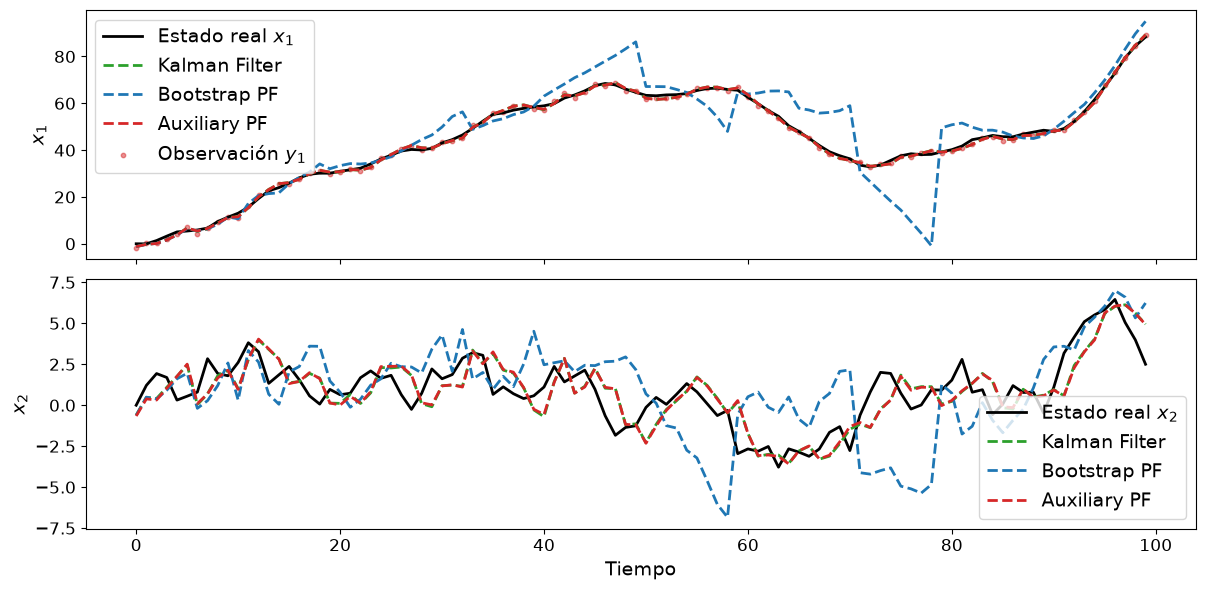

RMSE BPF: 7.078503999237449
RMSE APF: 1.121291668744337
RMSE KF: 1.1147049037406356


In [20]:
n=1000
i=5

estimates = {
    "Kalman Filter": results_kf[i]["results"]["estimates"],
    "Bootstrap PF": results_bpf[n][i]["results"]["estimates"],
    "Auxiliary PF": results_apf[n][i]["results"]["estimates"]
}

x_true = results_bpf[n][i]["x_true"]
y_obs = results_bpf[n][i]["y_obs"]

plot_results(x_true, y_obs, estimates, "Tiempo", "Comparación estado estimado (BPF y APF con N=10)")

print(f"RMSE BPF: {RMSE(x_true, results_bpf[n][i]["results"]["estimates"])}")
print(f"RMSE APF: {RMSE(x_true, results_apf[n][i]["results"]["estimates"])}")
print(f"RMSE KF: {RMSE(x_true, results_kf[i]["results"]["estimates"])}")

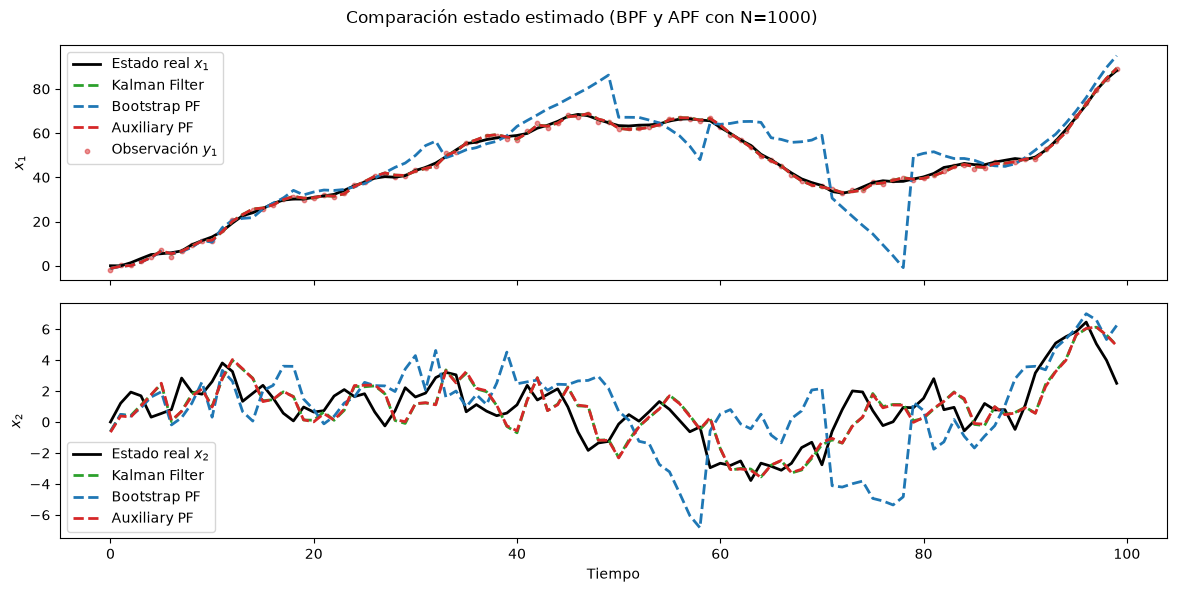

RMSE BPF: 7.078503999237449
RMSE APF: 1.121291668744337
RMSE KF: 1.1147049037406356


In [185]:
n=1000
i=5

estimates = {
    "Kalman Filter": results_kf[i]["results"]["estimates"],
    "Bootstrap PF": results_bpf[n][i]["results"]["estimates"],
    "Auxiliary PF": results_apf[n][i]["results"]["estimates"]
}

x_true = results_bpf[n][i]["x_true"]
y_obs = results_bpf[n][i]["y_obs"]

plot_results(x_true, y_obs, estimates, "Tiempo", "Comparación estado estimado (BPF y APF con N=1000)")

print(f"RMSE BPF: {RMSE(x_true, results_bpf[n][i]["results"]["estimates"])}")
print(f"RMSE APF: {RMSE(x_true, results_apf[n][i]["results"]["estimates"])}")
print(f"RMSE KF: {RMSE(x_true, results_kf[i]["results"]["estimates"])}")

### Influencia del ruido

En este apartado se va a comparar la influencia del ruido. La idea es utilizar un caso escalar y según los ruidos (dadas por las matrices de covarianza) comparar el funcionamiento de los algoritmos.

El sistema sería:

- Ecuación de estado:

$$
x_t = a x_{t-1} + w_t, \;\;\; w_t \sim N(0,q)
$$

- Ecuación de medición

$$
y_t = h x_t + v_t, \;\;\; v_t \sim N(0,r)
$$

En este caso se tendría
$$
A = \begin{bmatrix}
1 
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1  
\end{bmatrix}
$$

En el primer caso, se toma $r\gg q$, es decir las mediciones son poco informativas.

$$
q = 0.01 \;\; r=10
$$

In [8]:
# Matrices del modelo
A = np.array([[1.]])

H = np.array([[1.]])

q = np.array([[0.01]])

r = np.array([[10]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [9]:
# Modelo de transicion y obervacion
noise_transition = GaussianNoise(q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(r)
observation = AdditiveObservationModel(h, noise_observation)

In [19]:
# Simulacion
T = 500
x0 = np.array([[0.0]])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [20]:
# Bootstrap Particle Filter
bpf = BootstrapParticleFilter(N=1000, transition_model=transition, observation_model=observation)

bpf.initialize(mean=np.array([0.0]), cov=np.eye(1))

est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

In [21]:
# Auiliary Particle Filter
apf = AuxiliaryParticleFilter(N=1000, transition_model=transition, observation_model=observation)

apf.initialize(mean=np.array([0.0]), cov=np.eye(1))

est_apf = apf.run_filter(y_obs, resample_threshold=500)

In [22]:
# Ejecución filtro de Kalman
x0 = np.array([0.0])
P0 = np.eye(1)

kf = KalmanFilter(A, H, q, r, x0, P0)
est_kf = kf.run_filter(y_obs)

In [23]:
kalman_RMSE = RMSE(x_true, est_kf["estimates"])
kalman_loglikelihood = np.sum(est_kf["loglikelihoods"])

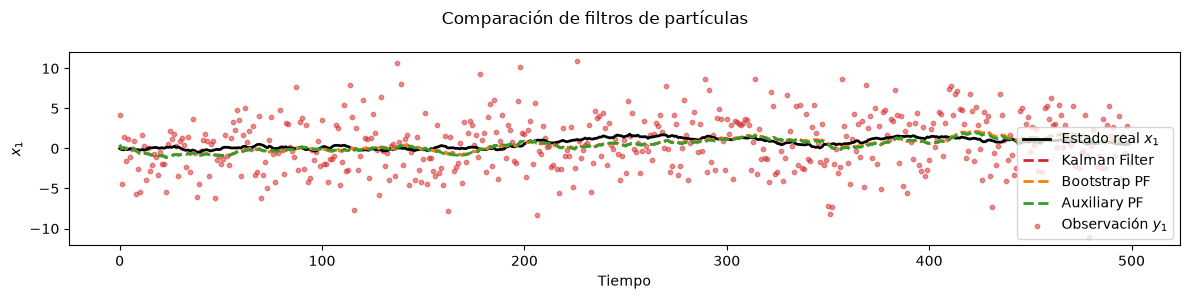

In [24]:
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
}

plot_results(x_true, y_obs, estimates)

In [26]:
#-----Comparativa resultados-----
print("RMSE")
print(f"Bootstrap Particle Filter: {RMSE(x_true, est_bpf["estimates"])}")
print(f"Auxiliary Particle Filter: {RMSE(x_true, est_apf["estimates"])}")
print(f"Filtro de Kalman: {kalman_RMSE}\n")

print("Numero resampling")
print(f"Bootstrap Particle Filter: {est_bpf["number_resamples"]}")
print(f"Auxiliary Particle Filter: {est_apf["number_resamples"]}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {est_bpf["log_likelihood"]}")
print(f"Auxiliary Particle Filter: {est_apf["log_likelihood"]}")
print(f"Filtro de Kalman: {kalman_loglikelihood}\n")

print("Cobertura de intervalos")
print(f"Bootstrap Particle Filter: {Interval_cover(x_true, est_bpf["intervals"])}")
print(f"Auxiliary Particle Filter: {Interval_cover(x_true, est_apf["intervals"])}")
print(f"Filtro de Kalman: {Interval_cover(x_true, est_kf["intervals"])}\n")



RMSE
Bootstrap Particle Filter: 0.5787361248184839
Auxiliary Particle Filter: 0.5696550221454616
Filtro de Kalman: 0.5763918096687819

Numero resampling
Bootstrap Particle Filter: 16
Auxiliary Particle Filter: 0

Log-verosimilitud estimada
Bootstrap Particle Filter: -1322.512288720732
Auxiliary Particle Filter: -1322.3494718712225
Filtro de Kalman: -1322.427246834156

Cobertura de intervalos
Bootstrap Particle Filter: 97.6
Auxiliary Particle Filter: 98.2
Filtro de Kalman: 98.0



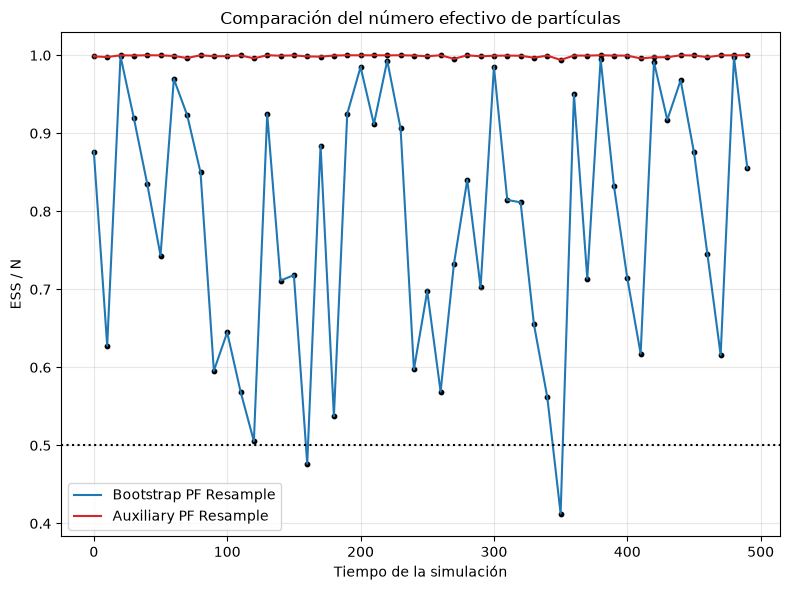

In [28]:
res_weights ={
    "Bootstrap PF Resample": est_bpf["normalized_weights"],
    "Auxiliary PF Resample": est_apf["normalized_weights"]
}

plot_ESS(res_weights, resampling_threshold=0.5)

En el segundo caso, se toma $q \gg r$, es decir, las mediciones aportan mucha información. 

In [29]:
q = np.array([[10]])

r = np.array([[0.01]])

In [30]:
# Modelo de transicion y obervacion
noise_transition = GaussianNoise(q)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = GaussianNoise(r)
observation = AdditiveObservationModel(h, noise_observation)

In [38]:
# Simulacion
T = 500
x0 = np.array([[0.0]])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [39]:
# Bootstrap Particle Filter
bpf = BootstrapParticleFilter(N=1000, transition_model=transition, observation_model=observation)

bpf.initialize(mean=np.array([0.0]), cov=np.eye(1))

est_bpf = bpf.run_filter(y_obs, resample_threshold=500)

In [40]:
# Auiliary Particle Filter
apf = AuxiliaryParticleFilter(N=1000, transition_model=transition, observation_model=observation)

apf.initialize(mean=np.array([0.0]), cov=np.eye(1))

est_apf = apf.run_filter(y_obs, resample_threshold=500)

In [41]:
# Ejecución filtro de Kalman
x0 = np.array([0.0])
P0 = np.eye(1)

kf = KalmanFilter(A, H, q, r, x0, P0)
est_kf = kf.run_filter(y_obs)

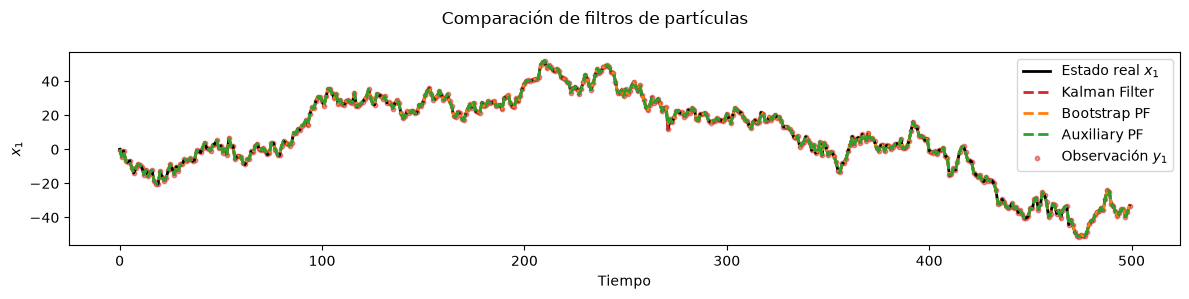

In [42]:
estimates = {
    "Kalman Filter": est_kf["estimates"],
    "Bootstrap PF": est_bpf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
}

plot_results(x_true, y_obs, estimates)

In [43]:
#-----Comparativa resultados-----
print("RMSE")
print(f"Bootstrap Particle Filter: {RMSE(x_true, est_bpf["estimates"])}")
print(f"Auxiliary Particle Filter: {RMSE(x_true, est_apf["estimates"])}")
print(f"Filtro de Kalman: {kalman_RMSE}\n")

print("Numero resampling")
print(f"Bootstrap Particle Filter: {est_bpf["number_resamples"]}")
print(f"Auxiliary Particle Filter: {est_apf["number_resamples"]}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {est_bpf["log_likelihood"]}")
print(f"Auxiliary Particle Filter: {est_apf["log_likelihood"]}")
print(f"Filtro de Kalman: {kalman_loglikelihood}\n")

print("Cobertura de intervalos")
print(f"Bootstrap Particle Filter: {Interval_cover(x_true, est_bpf["intervals"])}")
print(f"Auxiliary Particle Filter: {Interval_cover(x_true, est_apf["intervals"])}")
print(f"Filtro de Kalman: {Interval_cover(x_true, est_kf["intervals"])}\n")

RMSE
Bootstrap Particle Filter: 0.1929318842192869
Auxiliary Particle Filter: 0.16669053285461072
Filtro de Kalman: 0.5763918096687819

Numero resampling
Bootstrap Particle Filter: 500
Auxiliary Particle Filter: 500

Log-verosimilitud estimada
Bootstrap Particle Filter: -2007.7673653949082
Auxiliary Particle Filter: -4103.173480732729
Filtro de Kalman: -1322.427246834156

Cobertura de intervalos
Bootstrap Particle Filter: 93.4
Auxiliary Particle Filter: 87.4
Filtro de Kalman: 95.39999999999999



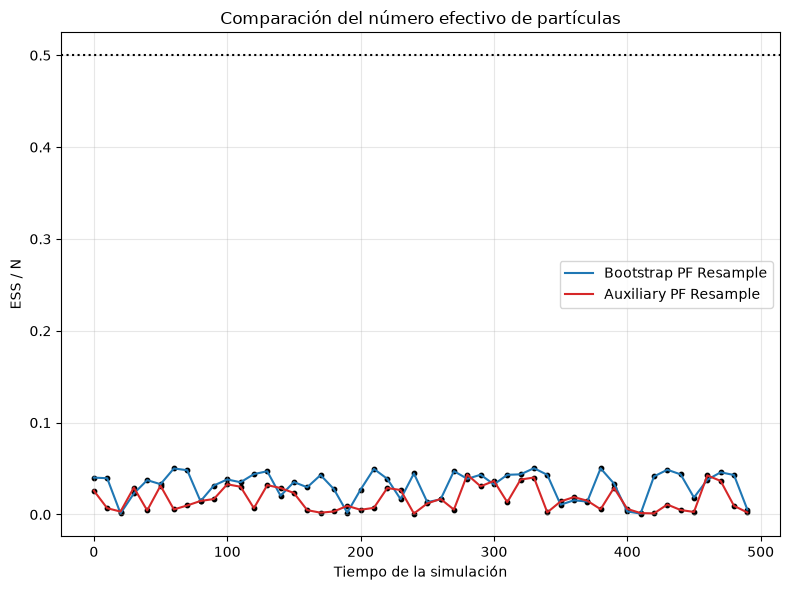

In [44]:
res_weights ={
    "Bootstrap PF Resample": est_bpf["normalized_weights"],
    "Auxiliary PF Resample": est_apf["normalized_weights"]
}

plot_ESS(res_weights, resampling_threshold=0.5)

### Distribuciones de ruido alternos

Ahora se vuelve al primer caso

- Ecuación de estado:

$$
x_t = A x_{t-1} + w_t
$$

- Ecuación de medición

$$
y_t = H x_t + v_t
$$

con

$$
A = \begin{bmatrix}
1 &1 \\
0 &1
\end{bmatrix}
\;\;
H = \begin{bmatrix}
1 &0 
\end{bmatrix}
$$

Sin embargo en este apartado, se va a tener distintas distribuciones a una nomral para el ruido de observación $v_t$. Así se verá cómo esta condición afecta al rendimiento del filtro de Kalman.  

Cabe destacar que las simulaciones se realizarán mediante las nuevas distribuciones para la ecuación de observación, pero para el filtro de Kalman se seguirá presuponiendo una distribución gaussiana con covarianza específica. Así, se pretende observar cómo de robusto es el filtro de Kalman cuando no se cumplen sus hipótesis.

In [2]:
from particle_filter.models.noise import GaussianNoise, OutliersNoise, StudentNoise, MultimodalNoise 

CASO 1: Outliers

Aquí la idea del ruido es imitar el hecho de que a veces se producen errores en los procesos de medición.

El ruido sigue una distribución:

$$

w_t = (1 - \epsilon_1)\;\mathcal{N}(v_t; 0, \sigma_1^2)+ \epsilon_2\;\mathcal{N}(v_t;0,\sigma^2_2)
$$
$$
v_t = (1 - \epsilon_2)\;\mathcal{N}(v_t; 0, \sigma^3)+ \epsilon_2\;\mathcal{N}(v_t;0,\sigma^2_4)
$$

con $\epsilon_1=0.05$, $\epsilon_2=0.10$, y:

$$
\sigma_1 = \begin{bmatrix}
0.01 &0.0\\
0.0 &1.0
\end{bmatrix}
\;\;
\sigma_2 = \begin{bmatrix}
100.0 &0.0\\
0.0 &100.0
\end{bmatrix}
\;\;
\sigma_3 = \begin{bmatrix}
1.0
\end{bmatrix}
\;\;
\sigma_4 = \begin{bmatrix}
100.0
\end{bmatrix}
$$


Para Kalman, se supone que todos los errores vienen de una gaussiana única con covarianza $\sigma$.

In [5]:
# Matrices del sistema 
A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

Q = sigma_1 = np.array([
    [0.01, 0.0],
    [0.0, 1.]
])

R = sigma_3 = np.array([[1.]])

sigma_2 = np.array([
    [100.0, 0.0],
    [0.0, 100.0]
])

sigma_4 = np.array([[100.]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [6]:
# Definición de los modelos de transición y observación
noise_transition = OutliersNoise(sigma_1, sigma_2)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = OutliersNoise(sigma_3, sigma_4)
observation = AdditiveObservationModel(h, noise_observation)

In [7]:
# Simulacion 
T = 500
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)


In [8]:
# Bootstrap Particle Filter
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
    )

bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_bpf = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

In [9]:
# Auxiliary Particle Filter
apf = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_apf = apf.run_filter(y_obs, resample_threshold=apf.N/2)

In [10]:
# Kalman Filter
x0 = np.array([0.0, 0.0])
P0 = np.eye(2)

kf = KalmanFilter(A, H, Q, R, x0, P0)
est_kf = kf.run_filter(y_obs)

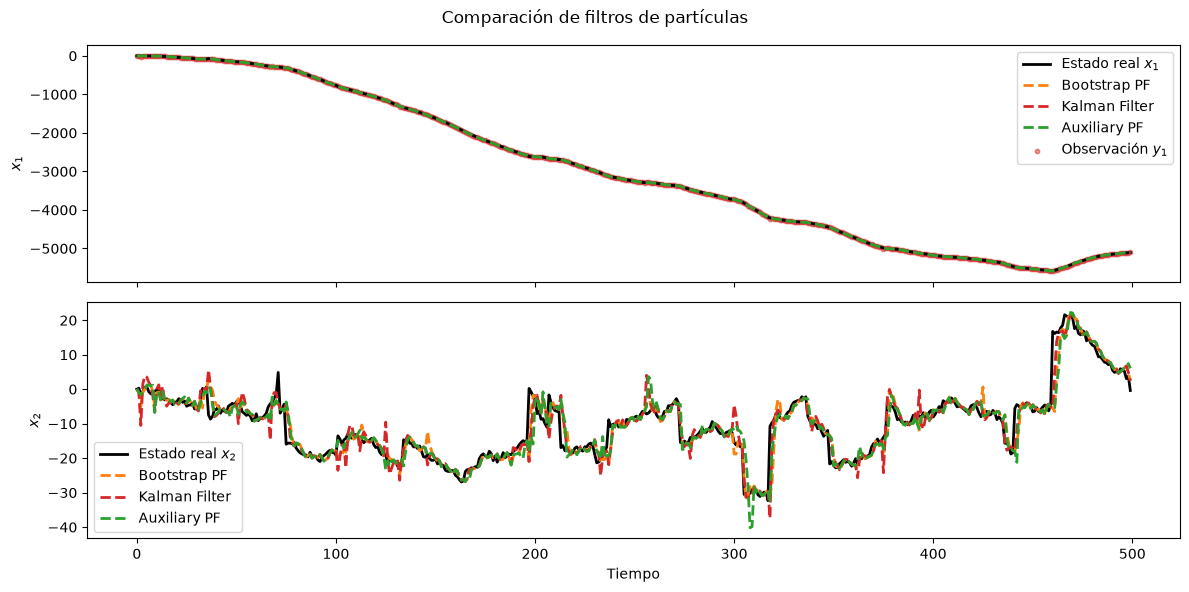

In [13]:
estimates = { 
    "Bootstrap PF": est_bpf["estimates"],
    "Kalman Filter": est_kf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
    } 

plot_results(x_true, y_obs, estimates)

In [14]:
#---Comparacion metricas---
print("RMSE")
print(f"Bootstrap Particle Filter: {RMSE(x_true, est_bpf["estimates"])}")
print(f"Auxiliary Particle Filter: {RMSE(x_true, est_apf["estimates"])}")
print(f"Filtro de Kalman: {RMSE(x_true, est_kf["estimates"])}\n")

print("Numero resampling")
print(f"Bootstrap Particle Filter: {est_bpf["number_resamples"]}")
print(f"Auxiliary Particle Filter: {est_apf["number_resamples"]}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {est_bpf["log_likelihood"]}")
print(f"Auxiliary Particle Filter: {est_apf["log_likelihood"]}")
print(f"Filtro de Kalman: {np.sum(est_kf["loglikelihoods"])}\n")

print("Cobertura de intervalos")
print(f"Bootstrap Particle Filter: {Interval_cover(x_true, est_bpf["intervals"])}")
print(f"Auxiliary Particle Filter: {Interval_cover(x_true, est_apf["intervals"])}")
print(f"Filtro de Kalman: {Interval_cover(x_true, est_kf["intervals"])}\n")

RMSE
Bootstrap Particle Filter: 3.1692683307555094
Auxiliary Particle Filter: 3.2504088196005827
Filtro de Kalman: 3.078877350551615

Numero resampling
Bootstrap Particle Filter: 380
Auxiliary Particle Filter: 108

Log-verosimilitud estimada
Bootstrap Particle Filter: -1447.0262278695868
Auxiliary Particle Filter: -1454.2799304025168
Filtro de Kalman: -3076.256051754396

Cobertura de intervalos
Bootstrap Particle Filter: 86.4
Auxiliary Particle Filter: 85.0
Filtro de Kalman: 72.2



CASO 2: Student

Ahora el ruido sigue una distribución t-Student:

$$
v_t​∼t_ν​(0,\sigma^2)
$$

$$
v_t​∼t_ν​(0,\sigma^2)
$$

con los grados de libertad igual a 3.

El filtro de Kalman supone, de nuevo $R=1$

In [15]:
# Matrices del sistema 
A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

Q = np.array([
    [0.01, 0.0],
    [0.0, 1.]
])

R = np.array([[1.]])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [16]:
# Definición de los modelos de transición y observación
noise_transition = StudentNoise(Q, 3)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = StudentNoise(R, 3)
observation = AdditiveObservationModel(h, noise_observation)

In [ ]:
# Simulacion 
T = 500
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [18]:
# Bootstrap Particle Filter
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
    )

bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_bpf = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

In [19]:
# Auxiliary Particle Filter
apf = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_apf = apf.run_filter(y_obs, resample_threshold=apf.N/2)

In [20]:
# Kalman Filter
x0 = np.array([0.0, 0.0])
P0 = np.eye(2)

kf = KalmanFilter(A, H, Q, R, x0, P0)
est_kf = kf.run_filter(y_obs)

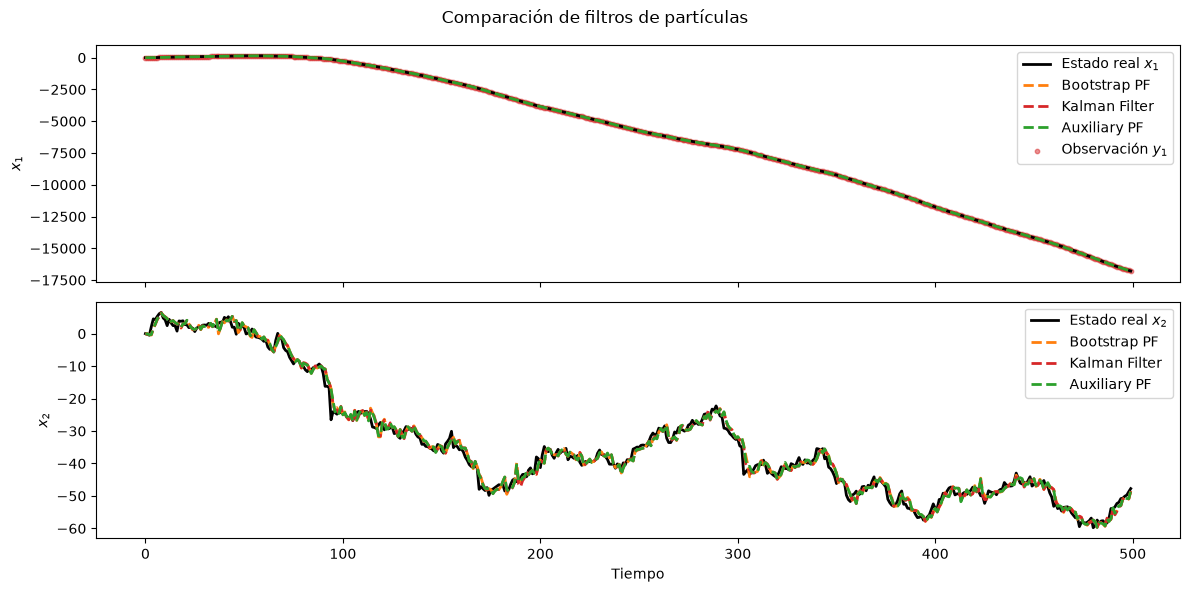

In [25]:
estimates = { 
    "Bootstrap PF": est_bpf["estimates"],
    "Kalman Filter": est_kf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
    } 

plot_results(x_true, y_obs, estimates)

In [22]:
print("RMSE")
print(f"Bootstrap Particle Filter: {RMSE(x_true, est_bpf["estimates"])}")
print(f"Auxiliary Particle Filter: {RMSE(x_true, est_apf["estimates"])}")
print(f"Filtro de Kalman: {RMSE(x_true, est_kf["estimates"])}\n")

print("Numero resampling")
print(f"Bootstrap Particle Filter: {est_bpf["number_resamples"]}")
print(f"Auxiliary Particle Filter: {est_apf["number_resamples"]}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {est_bpf["log_likelihood"]}")
print(f"Auxiliary Particle Filter: {est_apf["log_likelihood"]}")
print(f"Filtro de Kalman: {np.sum(est_kf["loglikelihoods"])}\n")

print("Cobertura de intervalos")
print(f"Bootstrap Particle Filter: {Interval_cover(x_true, est_bpf["intervals"])}")
print(f"Auxiliary Particle Filter: {Interval_cover(x_true, est_apf["intervals"])}")
print(f"Filtro de Kalman: {Interval_cover(x_true, est_kf["intervals"])}\n")

RMSE
Bootstrap Particle Filter: 1.5616395150381377
Auxiliary Particle Filter: 1.5241123144343052
Filtro de Kalman: 1.5161372729920248

Numero resampling
Bootstrap Particle Filter: 367
Auxiliary Particle Filter: 0

Log-verosimilitud estimada
Bootstrap Particle Filter: -1245.6131557444248
Auxiliary Particle Filter: -1239.4476717567393
Filtro de Kalman: -1323.7511626694068

Cobertura de intervalos
Bootstrap Particle Filter: 91.60000000000001
Auxiliary Particle Filter: 92.2
Filtro de Kalman: 75.4



CASO 3: Multimodal

En este caso es una distribución es una multimodal mezcla de varias distribuciones gaussianas. 

En particular:

$$
w_t \sim \alpha_1\; \mathcal{N}(\mu_1,\sigma_1^2) + (1- \alpha_1)\;\mathcal{N}(\mu_2, \sigma_2^2)
$$
$$
v_t \sim \alpha_2\; \mathcal{N}(\mu_3,\sigma_3^2) + (1- \alpha_2)\;\mathcal{N}(\mu_4, \sigma_4^2)
$$

Para el filtro de Kalman, la covarianza está dada por:

$$
Q = \alpha_1[\sigma_1^2 + (\mu_1 - \mu_{1v})^2] + (1-\alpha_1)[\sigma_2^2 + (\mu_2 - \mu_{1v})^2]
$$
$$
R = \alpha_2[\sigma_3^2 + (\mu_3 - \mu_{2v})^2] + (1-\alpha_2)[\sigma_4^2 + (\mu_4 - \mu_{2v})^2]
$$

donde $\mu_{1v} = \alpha_1 \mu_1 + (1-\alpha_2) \mu_2$ y $\mu_{2v}= \alpha_2 \mu_3 + (1-\alpha_2) \mu_4 $

In [3]:
# Matrices del sistema 
A = np.array([
    [1. , 1.],
    [0. , 1.]
])

H = np.array([
    [1., 0.]
])

def f(x):
    return A @ x

def h(x):
    return H @ x

In [4]:
means_transition = np.array([
    [-10.0, -10.0],
    [0.0, 0.0],
    [10.0, 10.0]
])

covs_transition = np.array([
    [[1.5 ** 2, 0.0], [0.0, 1.5**2]],
    [[0.5 ** 2, 0.0], [0.0, 0.5 ** 2]],
    [[1.5 ** 2, 0.0], [0.0, 1.5**2]]
])

weights_transition = np.array([
    0.25,
    0.5,
    0.25
])

mu_1v = np.sum(weights_transition * means_transition[:, 0])

Q = np.asarray( np.sum( weights_transition * ( covs_transition[:, 0, 0] + (means_transition[:, 0] - mu_1v)**2) ) )
Q = np.array([[Q]])

In [5]:
means_observation = np.array([
    [-10.0],
    [0.0],
    [10.0]
])

covs_observation = np.array([
    [[1.5 ** 2]],
    [[0.5 ** 2]],
    [[1.5 ** 2]]
])

weights_observation = np.array([
    0.25,
    0.5,
    0.25
])

mu_2v = np.sum(weights_observation * means_observation[:, 0])

R = np.asarray( np.sum( weights_observation * ( covs_observation[:, 0, 0] + (means_observation[:, 0] - mu_2v)**2) ) )
R = np.array([[R]])

In [6]:
# Modelos de transicion y observacion
noise_transition = MultimodalNoise(means_transition, covs_transition, weights_transition)
transition = AdditiveTransitionModel(f, noise_transition)

noise_observation = MultimodalNoise(means_observation, covs_observation, weights_observation)
observation = AdditiveObservationModel(h, noise_observation)

In [7]:
# Simulacion 
T = 500
x0 = np.array([0.0, 0.0])

x_true, y_obs = system_simulation(transition, observation, x0, T)

In [8]:
# Bootstrap Particle Filter
bpf = BootstrapParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
    )

bpf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_bpf = bpf.run_filter(y_obs, resample_threshold=bpf.N/2)

In [9]:
# Auxiliary Particle Filter
apf = AuxiliaryParticleFilter(
    N=1000,
    transition_model=transition,
    observation_model=observation
)

apf.initialize(mean=np.array([0.0, 0.0]), cov=np.eye(2))

est_apf = apf.run_filter(y_obs, resample_threshold=apf.N/2)

In [10]:
# Kalman Filter
x0 = np.array([0.0, 0.0])
P0 = np.eye(2)

kf = KalmanFilter(A, H, Q, R, x0, P0)
est_kf = kf.run_filter(y_obs)

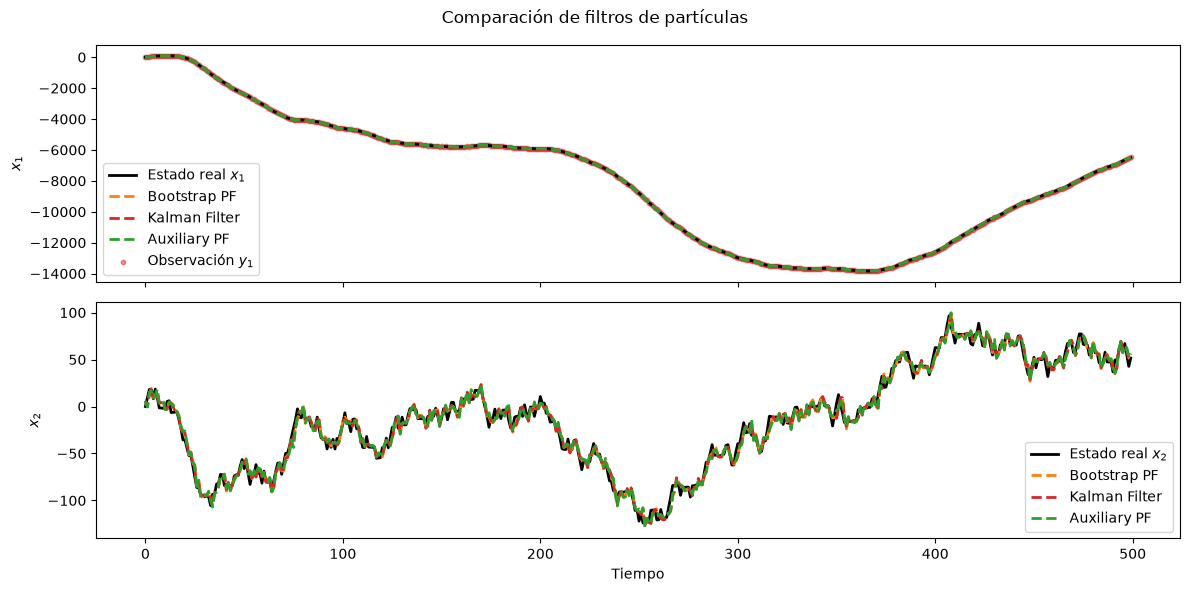

In [11]:
estimates = { 
    "Bootstrap PF": est_bpf["estimates"],
    "Kalman Filter": est_kf["estimates"],
    "Auxiliary PF": est_apf["estimates"]
    } 

plot_results(x_true, y_obs, estimates)

In [12]:
print("RMSE")
print(f"Bootstrap Particle Filter: {RMSE(x_true, est_bpf["estimates"])}")
print(f"Auxiliary Particle Filter: {RMSE(x_true, est_apf["estimates"])}")
print(f"Filtro de Kalman: {RMSE(x_true, est_kf["estimates"])}\n")

print("Numero resampling")
print(f"Bootstrap Particle Filter: {est_bpf["number_resamples"]}")
print(f"Auxiliary Particle Filter: {est_apf["number_resamples"]}\n")

print("Log-verosimilitud estimada")
print(f"Bootstrap Particle Filter: {est_bpf["log_likelihood"]}")
print(f"Auxiliary Particle Filter: {est_apf["log_likelihood"]}")
print(f"Filtro de Kalman: {np.sum(est_kf["loglikelihoods"])}\n")

print("Cobertura de intervalos")
print(f"Bootstrap Particle Filter: {Interval_cover(x_true, est_bpf["intervals"])}")
print(f"Auxiliary Particle Filter: {Interval_cover(x_true, est_apf["intervals"])}")
print(f"Filtro de Kalman: {Interval_cover(x_true, est_kf["intervals"])}\n")

RMSE
Bootstrap Particle Filter: 5.9360184441981945
Auxiliary Particle Filter: 6.126491141784726
Filtro de Kalman: 5.965904784825564

Numero resampling
Bootstrap Particle Filter: 500
Auxiliary Particle Filter: 499

Log-verosimilitud estimada
Bootstrap Particle Filter: -2052.468256816991
Auxiliary Particle Filter: -2222.324774118534
Filtro de Kalman: -2074.919457038426

Cobertura de intervalos
Bootstrap Particle Filter: 89.60000000000001
Auxiliary Particle Filter: 84.6
Filtro de Kalman: 91.2

